*Do not delete this style setting*

In [281]:
%%html
<style>
table {float:left}
</style>

# Session 3<br> A Simple Quantum Classifier

<table>
    <tr><td><strong>Aim:</strong></td>
        <td>To explore the creation and use of a simple quantum classifier in <strong>PennyLane</strong> and <strong>PyTorch</strong>.<br>
            Compare the quantum classifier with the equivalent classical classifier.<br>
            Note that "simplicity" is only in data and the model structure - not in the approach!</td></tr>
    <tr><td><strong>Author:</strong></td>
        <td>Jacob L. Cybulski (<a href="https://jacobcybulski.com/" target="_blank">website</a>),
            <em>Enquanted</em></td></tr>
    <tr><td><strong>Release:</strong></td>
        <td>April 2025</td></tr>
    <tr><td><strong>Updated:</strong></td>
        <td>October 2026</td></tr>
    <tr><td><strong>Datasets:</strong></td>
        <td>We will use the following two datasets from UCI repository (require: pip install ucimlrepo):<br>
        <ol>
            <li><a href="https://archive.ics.uci.edu/dataset/10/automobile" target="_blank">Automobiles</a>:
              This is a database of automobile specs. The aim is to determine its insurance risk (symboling). Data loading and preprocessing was included below.
              <font color="red">Note: As the website seems temporarily offline, a slightly different dataset has been made available for local access in "../data/Automobile.csv".</font></li>
            <li><a href="https://archive.ics.uci.edu/dataset/151/connectionist+bench+sonar+mines+vs+rocks" target="_blank">Sonar</a>:
              The aim is to discriminate between sonar signals bounced off a mine (metal cylinder) or a rock (roughly cylindrical).</li>
        </ol></td></tr>
    <tr><td><strong>Tasks:</strong></td>
        <td>40 minutes (unfinished tasks go to self-directed "challenges")</td></tr>
    <tr>
        <td></td>
        <td>Perform the following tasks<br>(record your observations at end of this notebook):<br>
        <ol>
            <li>Initially use the <strong><em>Automobiles</em></strong> dataset 1 (as provided).<br>
                Follow the instructor demonstration to step through the code.<br>
                - we will first look at a classical PyTorch model<br>
                - and then look at the quantum PyTorch+PennyLane model.</li>
            <li>Explore your dataset and think of its impact on the process and results:<br>
                - hint: consider data ordering and what needs to be done about it</li>
            <li>Can you improve the model performance by changing the approach<br>to dimensionality reduction:<br>
                - feature selection based on intuition (default) ?<br>
                - feature selection based on f_classif, mutual_info_classif, chi2 ?<br>
                - dimensionality reduction based on PCA ?<br>
                Which of these approaches had the greatest impact on performance?</li>
            <li>Improve the model by varying its architectural and training aspects.<br>
                - changes may apply to data, model and its training<br>
                - what methods have you applied and with what result ?</li>
            <li>Change your PennyLane and Torch model to allow application of<br>
                - <b>sigmoid</b> final activation function, and<br>
                - <b>BCELoss</b> cost function.<br>
                Note 1: You may need to change the quantum measurement to probability.<br>
                Note 2: You may need to add an extra layer mapping qlayer output to BCELoss.</li>
            <li>Create some data on the fantasy automobiles and use the developed model for<br>
                their classification. Does it match your expectation?</li>
            <li>Critically assess the model, its development and training!<br>
                - What principles of quantum model development were broken in the process?</li>
            <li>Compare the classical vs quantum classification models and their performance.</li>
            <li>Reflect on this session.</li>
        </ol></td>
    </tr>
    <tr>
        <td><strong>Challenge<br>Tasks:</strong></td>
        <td>Perform one or more of the following tasks in your own time:<br/>
        <ol style="list-style-type: upper-alpha;">
            <li>Complete the unfinished tasks.</li>
            <li>Change the quantum model by incorporating a full-reuploading ansatz.</li>
            <li>Cleanup and add nominal features to this analysis.</li>
            <li>Add an ROC curve analysis for the best model result (research).</li>
            <li>Include the quantum model definition as part of the <strong><em>Quantum_Auto</em></strong> class.</li>
            <li>Change (back) the label variable from binary to multiclass (hard), <br>
                to implement and test a multinomial classification model (research).</li>
            <li>Create a confusion matrix, with sensitivity and specificity for each class (research).</li>
            <li>Address the critical flaws in the model and its development process.<br>
                - Did you have to retrace the entire experimental process?<br>
                - What is the quantum performance afterwards?<br>
                - What does it mean?</li>
            <li>Apply and adapt your completed model to the <strong><em>Sonar</em></strong> data set 2</li>
        </ol></td>
    </tr>
    <tr><td><strong>References:</strong></td>
        <td><ul>
            <li><a href = "https://www.youtube.com/watch?v=OIenNRt2bjg" target="_blank">
                AssemblyAI, “PyTorch Crash Course - Getting Started with Deep Learning”,<br>YouTube Video, Jul 2022.</a></li>
            <li><a href = "https://pennylane.ai/qml/demos/tutorial_qnn_module_torch" target="_blank">Thomas Bromley, "Turning quantum nodes into Torch Layers",<br>
                PennyLane Demo, October 7, 2024.</a></li>
            <li><a href = "https://docs.pennylane.ai/en/stable/code/api/pennylane.qnn.TorchLayer.html" target="_blank">PennyLane, "qml.qnn.TorchLayer",<br>
                PennyLane Documentation, Code API, 2025.</a></li>
            <li><a href = "https://pennylane.ai/qml/demos/tutorial_local_cost_functions" target="_blank">Thomas Storwick, "Alleviating barren plateaus with local cost functions",<br>
                PennyLane Tutorial, November 6, 2024.</a></li>
        </ul></td>
    </tr>
    <tr><td><strong>License:</strong></td>
        <td>This project is licensed under the
            <a href="https://www.gnu.org/licenses/gpl-3.0.en.html" target="_blank">GNU General Public License v3</a></td></tr>
    <tr><td><strong>Changes:</strong></td>
        <td>All significant changes to this code must be recorded in this notebook</td></tr>
</table>

## Libraries

In [282]:
import sys
sys.path.append('.')
sys.path.append('..')
sys.path

['c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\python312.zip',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\DLLs',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312',
 '',
 'C:\\Users\\codeg\\AppData\\Roaming\\Python\\Python312\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32\\lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\pythonwin',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..',
 '.',
 '..']

In [283]:
### General libraries

import os
import pylab
import math
import time
import copy
import pandas as pd
from IPython.display import clear_output

import matplotlib.pyplot as plt
from matplotlib import set_loglevel
set_loglevel("warning")

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [284]:
### Import utilities
from utilities import multi_plot_hist, multi_plot_series, draw_circuit

In [285]:
### Import PennyLane and Torch
import pennylane as qml
from pennylane import numpy as np
from pennylane import NesterovMomentumOptimizer
from torch import nn
from torch.autograd import Variable
import torch

---

## <font color="blue">Data preparation</font>

Selected dataset: <a href="https://archive.ics.uci.edu/dataset/10/automobile" target="_blank">Automobiles</a>.
  
<font color="CornflowerBlue">_**Data needs to be prepared as follows:**_</font>

- <font color="CornflowerBlue">*Load and understand data*</font>
- <font color="CornflowerBlue">*Select numerical variables only (make it simple)*</font>
- <font color="CornflowerBlue">*Eliminate missing values*</font>
- <font color="CornflowerBlue">*Prepare the label (change it to binary)*</font>
- <font color="CornflowerBlue">*Standardise predictors*</font>
- <font color="CornflowerBlue">*Reduce dimensionality*</font>

In [286]:
### Dataset settings
n_features = 5
data_seed = 2025

### Load and understand data
*The original source of data included for reference.*

In [287]:
#from ucimlrepo import fetch_ucirepo

# auto = fetch_ucirepo(id=10)
# X_vars = auto.data.features 
# y_class = auto.data.targets 
# print(auto.metadata['additional_info']['summary'],'\n') 

In [288]:
import pandas as pd

### Fetch data from the local repository
filepath = '../data/Automobile.csv'
headers = ['symboling','normalized-losses','make','fuel-type','aspiration', 'num-of-doors','body-style',
           'drive-wheels','engine-location','wheel-base', 'length','width','height','curb-weight','engine-type',
           'num-of-cylinders', 'engine-size','fuel-system','bore','stroke','compression-ratio','horsepower',
           'peak-rpm','city-mpg','highway-mpg','price']

automobile = pd.read_csv(filepath, sep='#', decimal='.', header=None, names=headers)
print(f'\nRead "automobile" dataset, with rows={automobile.shape[0]}, columns={automobile.shape[1]}\n')


Read "automobile" dataset, with rows=238, columns=26



In [289]:
automobile.head(5)

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


### Preliminary data processing

In [290]:
### Split data frame into X and y vectors
y_class = automobile[['symboling']]
X_vars = automobile.drop(columns=['symboling'])

In [291]:
### After a brief investigation, it is evident that ...
#   this data set has a serious problem and cannot be used as it is!
...

Ellipsis

### Select numerical predictors only

In [292]:
### Select numeric columns only
X_sel = X_vars.select_dtypes(include=np.number)
X_sel.columns

Index(['normalized-losses', 'wheel-base', 'length', 'width', 'height',
       'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'],
      dtype='object')

### Deal with missing values

In [293]:
### Identify columns with missing values
X_sel.isna().sum().loc[lambda x : x > 0].sort_index()

bore                  4
horsepower            2
normalized-losses    47
peak-rpm              2
price                 4
stroke                4
dtype: int64

In [294]:
### Replace missing values with column mean
#   Then check that missing values have been eliminated
auto_xmean = X_sel.mean()
X_sel = X_sel.fillna(auto_xmean)
X_sel.isna().sum().loc[lambda x : x > 0]

Series([], dtype: int64)

### Standardise predictors

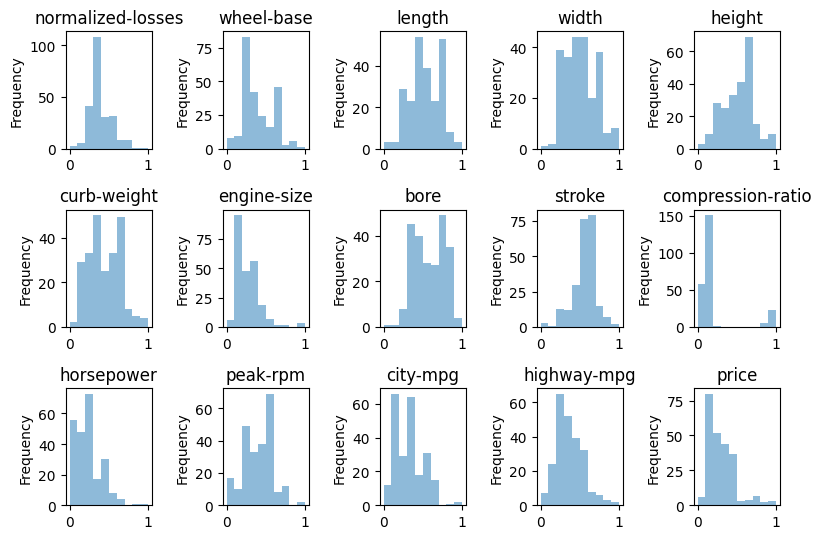

In [295]:
# Standardise all variables
from sklearn.preprocessing import StandardScaler, MinMaxScaler
auto_scaler = MinMaxScaler(feature_range=(0, 1)) 
scaled = auto_scaler.fit_transform(X_sel) 
X_std = pd.DataFrame(scaled, columns=X_sel.columns)
multi_plot_hist(X_std, n_cols = 5, figsize=(8,5.5));

### Prepare the label
<font color="CornflowerBlue">As the label is numeric and multi-class, to simplify the task we turn the label into a binary variable.<br>
The binary class split will be around the distribution mean.</font>

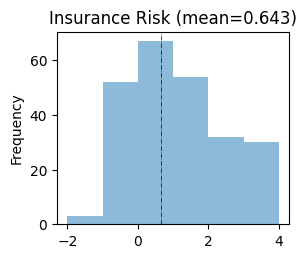

In [296]:
### Observe label distribution
auto_ymean = y_class["symboling"].mean()
ax = y_class.plot.hist(bins=6, alpha=0.5, title=f'Insurance Risk (mean={round(auto_ymean, 3)})', 
                       figsize=(3,2.5))
ax.get_legend().remove()
plt.axvline(auto_ymean, color='k', linestyle='-.', linewidth=0.5);

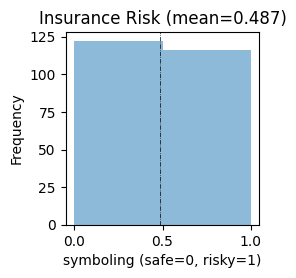

In [297]:
### Create a binary label
pd.set_option('display.max_rows', 10)
y_std = pd.DataFrame(y_class)
y_std['symboling'] = np.where(y_std['symboling'] > auto_ymean, 1, 0)
y_binmean = y_std["symboling"].mean()

ax = y_std.plot.hist(bins=2, alpha=0.5, title=f'Insurance Risk (mean={np.round(y_binmean, 3)})', 
                 figsize=(2.5,2.5))
ax.set_xlabel(f'{y_std.columns[0]} (safe=0, risky=1)')
ax.get_legend().remove()
plt.axvline(y_binmean, color='k', linestyle='-.', linewidth=0.5);

### Reduce data dimensionality
Note that we should somehow reduce data dimensionality.

In [298]:
### The number of features to select
col_names = list(X_std.columns)
print(f'\nNumber of features available: {X_std.shape[1]}\n'+\
      f'Number of features to select: {n_features}\n\n'+\
      f'Features: {*col_names,}')


Number of features available: 15
Number of features to select: 5

Features: ('normalized-losses', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price')


#### Feature selection based on intuition

In [299]:
X_hunch = X_std[['engine-size', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower']]
X_hunch.columns

Index(['engine-size', 'highway-mpg', 'city-mpg', 'peak-rpm', 'horsepower'], dtype='object')

#### Feature selection based on statistical analysis (ANOVA F-test or $\chi^2$)

In [300]:
from sklearn.feature_selection import SelectKBest, chi2, f_classif, mutual_info_classif

# Feature extraction
selector = SelectKBest(score_func=f_classif, k=n_features)
X_ext = selector.fit_transform(X_std, y_std)

# Identify selected features
columns_mask = selector.get_support()
sel_features = X_std.columns[columns_mask]
X_kbest = pd.DataFrame(data = X_ext, columns = sel_features)
X_kbest.columns

Index(['wheel-base', 'length', 'width', 'height', 'curb-weight'], dtype='object')

#### Dimensionality reduction with PCA

In [301]:
from sklearn.decomposition import PCA

n_components = n_features
auto_pca = PCA(n_components=n_components)
X_pca = auto_pca.fit_transform(X_std)
X_pca = pd.DataFrame(X_pca, columns=[f'PC{n:02d}' for n in range(X_pca.shape[1])])
pca_var = auto_pca.explained_variance_ratio_
print(f'Explained var = {np.sum(pca_var):02.3f}')
X_pca.columns

Explained var = 0.863


Index(['PC00', 'PC01', 'PC02', 'PC03', 'PC04'], dtype='object')

#### Select an approach to dimensionality reduction
<font color="CornflowerBlue">Select the method of dimensionality reduction by copying the required version of X.<br>
All versions have been defined above.</font>

In [302]:
X = X_pca.copy() #X_hunch X_kbest  X_pca  
y = y_std.copy()

***

## <font color="blue">Model development</font>

### Utilities

In [303]:
### Performance measures

### A simple MSE cost function
def square_mse(labels, predictions):
    sq_diffs = torch.tensor([(l - p)**2 for l, p in zip(labels, predictions)])
    return sq_diffs.mean().item()

### Calculates accuracy from expval predictions
def accuracy(labels, predictions, prec=1e-5):
    acc = sum(abs(l - p) < prec for l, p in zip(labels, predictions))
    acc = acc / len(labels)
    return acc.item()

### Counts the number of pytorch model parameters
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

### Define device to compute on

In [304]:
### Find what devices are available

# Enable CUDA device if available
torch_device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f'\nThe available devices:\t\t{torch_device}')

# Force CPU to avoid moving computation and data back and from the GPU
torch_device = "cpu"

print(f'PyTorch device to be used:\t{torch_device}\n')


The available devices:		cpu
PyTorch device to be used:	cpu



### Model and training configuration

In [305]:
### Data params
n_data = X.shape[0]
x_angle_margin = 0.1
x_angle_min = 0+x_angle_margin
x_angle_max = np.pi-x_angle_margin

### Training params
epochs = 400    # 50 # 80 # 100 # 300
log_interv = 1   # History to be saved only once every interv or epochs
acc_prec = 0.5   # Precision of accuracy calculation
shots = None     # None means using theoretical frequency distribution 
seed = 2025

### Prepare data exactly as for the quantum classifier

<font color="CornflowerBlue">Note that we have already scaled the X values to the [0..1] range.<br>
That value range was needed to perform PCA, if this dimensionality reduction was to be used.<br>
We could not scale X to the range of values [0..pi] as required for quantum data encoding,<br>
as PCA would have changed that range later on.</font>

In [306]:
### Standardise X values to the range 0+margin..pi-margin
from sklearn.preprocessing import StandardScaler, MinMaxScaler
angle_scaler = MinMaxScaler(feature_range=(x_angle_min, x_angle_max)) 
scaled = angle_scaler.fit_transform(X) 
X = pd.DataFrame(scaled, columns=X.columns)

In [307]:
### Create data partitions
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X.iloc[:,0:n_data], y.iloc[:,0:n_data], 
    test_size=0.33, shuffle=True, random_state=seed)
print(f'Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}')

Shapes: X_train=(159, 5), X_test=(79, 5), y_train=(159, 1), y_test=(79, 1)


In [308]:
### Change the data format to tensors
X_train_tens = torch.tensor(np.array(X_train), dtype=torch.double)
y_train_tens = torch.tensor(np.array(y_train), dtype=torch.double)
X_test_tens  = torch.tensor(np.array(X_test), dtype=torch.double)
y_test_tens  = torch.tensor(np.array(y_test), dtype=torch.double)

### PyTorch model with PennyLane layer

<font color="CornflowerBlue">To use PennyLane Torch layers refer to the 
<a href="https://docs.pennylane.ai/en/stable/code/api/pennylane.qnn.TorchLayer.html" target="_blank">TorchLayer PennyLane API</a>
as well as <a href = "https://pennylane.ai/qml/demos/tutorial_qnn_module_torch" target="_blank">Thomas Bromley tute on Torch layers</a>.</font>

In [309]:
### Classic classifier
class Classic_Auto(nn.Module):

    def __init__(self, in_shape, out_shape):
        super(Classic_Auto, self).__init__()

        # self.model = nn.Sequential(
        #     nn.Linear(in_shape, 32),
        #     nn.ReLU(),
        #     nn.Linear(32, 64),
        #     nn.ReLU(),
        #     nn.Linear(64, 32),
        #     nn.ReLU(),
        #     nn.Linear(32, 8),
        #     nn.ReLU(),
        #     nn.Linear(8, out_shape)
        # )
        
        layers = self.layers(in_shape, out_shape)
        self.model = nn.Sequential(*layers)
        
    def layers(self, in_shape, out_shape):
        
        clayer_0 = torch.nn.Linear(in_shape, 32)#32, 64, 32, 8
        clayer_1 = torch.nn.ReLU()
        clayer_2 = torch.nn.Linear(32, 64)
        clayer_3 = torch.nn.ReLU()
        clayer_4 = torch.nn.Linear(64, 32)
        clayer_5 = torch.nn.ReLU()
        clayer_6 = torch.nn.Linear(32, 8)
        clayer_7 = torch.nn.ReLU()
        clayer_8 = torch.nn.Linear(8, out_shape)    
        clayer_9 = torch.nn.Sigmoid()    
        
        layers = [clayer_0, clayer_1, clayer_2, clayer_3, clayer_4, clayer_5,
                 clayer_6, clayer_7, clayer_8, clayer_9]
        return layers

    def forward(self, x):
        x = self.model(x)
        return x

### Test the classical PyTorch model before use

In [310]:
### Create a test model and draw the test model circuit
test = Classic_Auto(in_shape=X_train_tens.shape[1], out_shape=y_train_tens.shape[1]).double().to(torch_device)

print(f'\nCM weights: {count_params(test)}, Epochs: {epochs}')
print(f'\nTest results: {test(X_train_tens[0:5])}\n')
test.eval()


CM weights: 4657, Epochs: 400

Test results: tensor([[0.4232],
        [0.4238],
        [0.4239],
        [0.4245],
        [0.4235]], dtype=torch.float64, grad_fn=<SigmoidBackward0>)



Classic_Auto(
  (model): Sequential(
    (0): Linear(in_features=5, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): ReLU()
    (6): Linear(in_features=32, out_features=8, bias=True)
    (7): ReLU()
    (8): Linear(in_features=8, out_features=1, bias=True)
    (9): Sigmoid()
  )
)

### Creation and training of the PennyLane/PyTorch model

In [311]:
### Trains a PyTorch model (of any kind)
def train_model(model, X, y, cost_fun, optimizer, epochs, 
                log_interv=100, prompt_fract=0.1, start_train_time=0):
    
    history = []
    opt_params = {}
    hist_params = []
    min_epoch = 0
    min_cost = np.inf
    if start_train_time == 0: start_train_time = time.time()
    
    model.train()
    for epoch in range(epochs):
        
        optimizer.zero_grad()
        output = model(X)
        cost = cost_fun(output, y)
        cost.backward()
        optimizer.step()

        curr_cost = cost.item()
        if curr_cost < min_cost: 
            min_cost = curr_cost
            min_epoch = epoch
            opt_params = copy.deepcopy(model.state_dict())

        if epoch % log_interv == 0:
            history.append(curr_cost)
            hist_params.append(copy.deepcopy(model.state_dict()))

        elapsed_train_time = time.time() - start_train_time
        if (prompt_fract == 0) or (epoch % int(prompt_fract*epochs) == 0):
            print(f'{epoch: 5d} '+ \
                  f'({elapsed_train_time:06.0f} sec): '+ \
                  f'Cost {curr_cost:6.4g}')
            
    return history, opt_params, hist_params, (min_epoch, min_cost)

### Training loop

In [312]:
### Ensure repeatability
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

### Create a model
c_auto = Classic_Auto(in_shape=X_train_tens.shape[1], out_shape=y_train_tens.shape[1]).double().to(torch_device)

### Loss and optimiser
cost_fun = nn.BCELoss() #MSELoss

# opt = optim.SGD(model.parameters(),lr=0.01,weight_decay=1e-5)
# opt = torch.optim.Adam(c_auto.parameters())
opt = torch.optim.NAdam(c_auto.parameters(), lr=0.001) #0.001

### Train the model
prompt_fract = 0.1
start_train_time = time.time()
print(f'\nTraining the model:')

train_obj_hist, opt_params, hist_params, opt_point = \
    train_model(c_auto, X_train_tens, y_train_tens, cost_fun, opt, epochs, 
                log_interv=log_interv, prompt_fract=prompt_fract)
elapsed_train_time = time.time() - start_train_time

### Print the training summary
train_min_obj = np.min(train_obj_hist)
train_min_obj_iter = np.argmin(train_obj_hist)

time_str = time.strftime("%H:%M:%S", time.gmtime(elapsed_train_time))
print(f'\nTraining completed: epochs={epochs} '+\
      f'in {elapsed_train_time:0.0f}sec ({time_str})\n\t'+
      f'min MSE = {np.round(train_min_obj, 5):05.4f} @ {train_min_obj_iter:04d}')


Training the model:
    0 (000000 sec): Cost 0.6976


   40 (000000 sec): Cost 0.6147
   80 (000000 sec): Cost 0.5432
  120 (000000 sec): Cost 0.4821
  160 (000000 sec): Cost 0.4323
  200 (000000 sec): Cost 0.4033
  240 (000001 sec): Cost 0.3784
  280 (000001 sec): Cost 0.3594
  320 (000001 sec): Cost 0.3151
  360 (000001 sec): Cost 0.2873

Training completed: epochs=400 in 1sec (00:00:00)
	min MSE = 0.2633 @ 0398


### Calculate training and testing scores

In [313]:
### Calculate a model score as defined by the scoring function and data
def score_model(model, params, X, y, score_fun, score_name='Score', score_min=True, prompt_fract=0):

    ### Initialise scoring
    score_hist = []
    if score_min:
        opt_score = float(np.inf)
    else:
        opt_score = -float(np.inf)
    
    ### Calculate scores
    print(f'\nCalculating scores for {score_name}:')
    for iter in range(len(hist_params)):
        model.load_state_dict(params[iter])
        pred = model(X)
        curr_score = score_fun(pred, y)
        if type(curr_score) is torch.Tensor:
            curr_score = curr_score.item()
        score_hist.append(curr_score)
        if (not score_min and (curr_score > opt_score)) or \
           (score_min and (curr_score < opt_score)):
            opt_score = curr_score
            opt_score_iter = iter
        if (prompt_fract == 0) or (iter % int(prompt_fract*epochs) == 0):
            print(f'{iter:5d} / {epochs:3d}, '+
                  f'{score_name} = {curr_score:.6f}')
    return score_hist, opt_score, opt_score_iter

In [314]:
### Calculate remaining scores
#   Note: training costs (MSE) have already been calculated

start_score_time = time.time()

train_acc_hist, train_max_acc, train_max_acc_iter = \
    score_model(c_auto, hist_params, X_train_tens, y_train_tens, 
    lambda pred, targ: accuracy(pred, targ, prec=acc_prec), 
    score_name='Train Acc', score_min=False, prompt_fract=prompt_fract)
test_obj_hist, test_min_obj, test_min_obj_iter = \
    score_model(c_auto, hist_params, X_test_tens, y_test_tens, cost_fun, 
    score_name='Test MSE', score_min=True, prompt_fract=prompt_fract)
test_acc_hist, test_max_acc, test_max_acc_iter = \
    score_model(c_auto, hist_params, X_test_tens, y_test_tens, 
    lambda pred, targ: accuracy(pred, targ, prec=acc_prec), 
    score_name='Test Acc', score_min=False, prompt_fract=prompt_fract)

elapsed_score_time = time.time() - start_score_time
score_time_str = time.strftime("%H:%M:%S", time.gmtime(elapsed_score_time))

print(f'\nScoring completed: epochs={epochs} '+\
      f'in {elapsed_score_time:0.0f} sec ({score_time_str})\n')


Calculating scores for Train Acc:
    0 / 400, Train Acc = 0.465409
   40 / 400, Train Acc = 0.666667
   80 / 400, Train Acc = 0.748428
  120 / 400, Train Acc = 0.792453
  160 / 400, Train Acc = 0.842767
  200 / 400, Train Acc = 0.849057
  240 / 400, Train Acc = 0.861635
  280 / 400, Train Acc = 0.823899
  320 / 400, Train Acc = 0.874214
  360 / 400, Train Acc = 0.867925

Calculating scores for Test MSE:
    0 / 400, Test MSE = 0.688754
   40 / 400, Test MSE = 0.611009
   80 / 400, Test MSE = 0.519097
  120 / 400, Test MSE = 0.449409
  160 / 400, Test MSE = 0.398157
  200 / 400, Test MSE = 0.383926
  240 / 400, Test MSE = 0.383048
  280 / 400, Test MSE = 0.404001
  320 / 400, Test MSE = 0.396460
  360 / 400, Test MSE = 0.417764

Calculating scores for Test Acc:
    0 / 400, Test Acc = 0.531646
   40 / 400, Test Acc = 0.645570
   80 / 400, Test Acc = 0.835443
  120 / 400, Test Acc = 0.848101
  160 / 400, Test Acc = 0.860759
  200 / 400, Test Acc = 0.835443
  240 / 400, Test Acc = 0.873

In [315]:
### Run summary
train_time_str = time.strftime("%H:%M:%S", time.gmtime(elapsed_train_time))
print(f'\nCompleted model training and scoring\n\nSummary of model training run '+
      f'(params = {count_params(c_auto)}, epochs = {epochs})\n\n\t'+
      f'training: MSE = {np.round(train_min_obj, 5):05.4f} @ {train_min_obj_iter:04d}, '+
      f'ACC = {np.round(train_max_acc, 5):05.4f} @ {train_max_acc_iter:04d}\n\t'+
      f'testing:  MSE = {np.round(test_min_obj, 5):05.4f} @ {test_min_obj_iter:04d}, '+
      f'ACC = {np.round(test_max_acc, 5):05.4f} @ {test_max_acc_iter:04d}\n\n'+
      f'Time: training = {elapsed_train_time:0.0f} sec ({train_time_str}), '+
      f'scoring = {elapsed_score_time:0.0f} sec ({score_time_str})\n\t'+
      f'\n'
     )


Completed model training and scoring

Summary of model training run (params = 4657, epochs = 400)

	training: MSE = 0.2633 @ 0398, ACC = 0.8805 @ 0313
	testing:  MSE = 0.3746 @ 0243, ACC = 0.8861 @ 0274

Time: training = 1 sec (00:00:00), scoring = 2 sec (00:00:02)
	



### Plot costs and scores

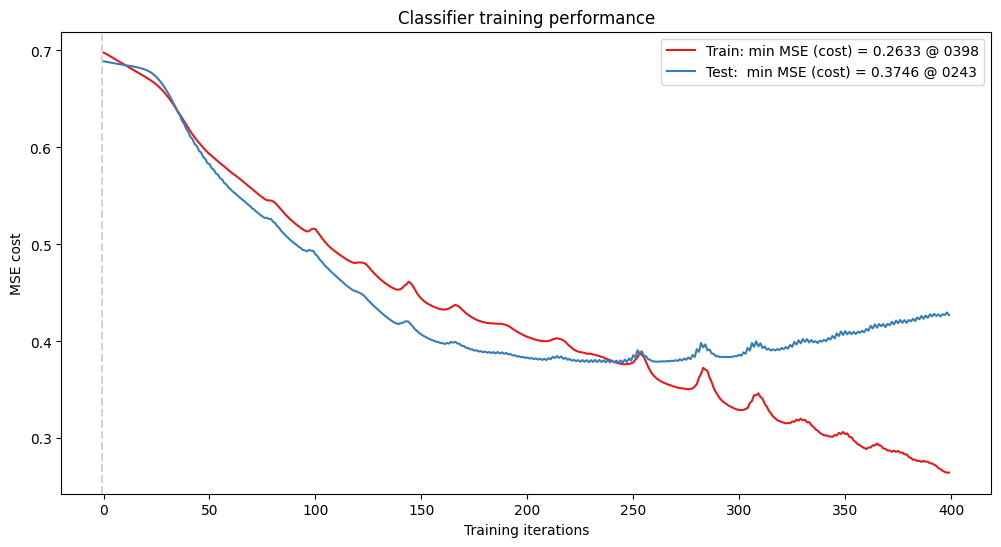

In [316]:
train_label = f'Train: min MSE (cost) = {round(train_min_obj, 5):05.4f} @ {train_min_obj_iter:04d}'
test_label =  f'Test:  min MSE (cost) = {round(test_min_obj, 5):05.4f} @ {test_min_obj_iter:04d}'
multi_plot_series(
    [train_obj_hist, test_obj_hist], X_list=[0, 0], labels=[train_label, test_label], 
    lines=['solid', 'solid'], # colors=None, markers=None, marker_colors=None,
    rcParams=(12, 6), xlabel='Training iterations', ylabel='MSE cost',
    legend_cols=1, smooth_weight=0.6, title='Classifier training performance')

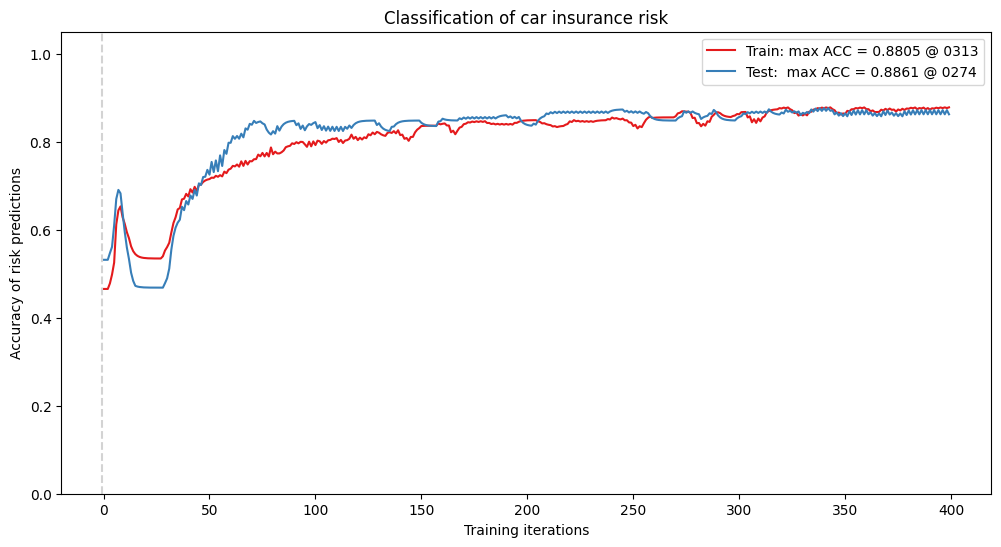

In [317]:
train_label = f'Train: max ACC = {round(train_max_acc, 5):05.4f} @ {train_max_acc_iter:04d}'
test_label =  f'Test:  max ACC = {round(test_max_acc, 5):05.4f} @ {test_max_acc_iter:04d}'
multi_plot_series(
    [train_acc_hist, test_acc_hist], X_list=[0, 0], labels=[train_label, test_label], 
    lines=['solid', 'solid'], ylim=(0, 1.05), # colors=None, markers=None, marker_colors=None,
    rcParams=(12, 6), xlabel='Training iterations', ylabel='Accuracy of risk predictions',
    legend_cols=1, smooth_weight=0.6, title='Classification of car insurance risk')

In [320]:
### Task 6: Evaluation with fantasy automobiles
# 1. Compact sports car (Powerful, low, expensive, and high risk)
car_sport = X_sel.mean().copy()
car_sport['wheel-base']        = 89.0    # Short and agile
car_sport['length']            = 168.0
car_sport['height']            = 50.0    # Very low (aerodynamic)
car_sport['curb-weight']       = 2700.0
car_sport['horsepower']        = 260.0   # High horsepower
car_sport['price']             = 35000.0 # Expensive
car_sport['normalized-losses'] = 160.0   # High claims history

# 2. Sturdy Family Sedan (Volvo-style: long, tall, heavy, and safe)
car_family = X_sel.mean().copy()
car_family['wheel-base']        = 108.0   # Long wheelbase
car_family['length']            = 188.0   # Long and spacious
car_family['height']            = 56.0    # Tall
car_family['curb-weight']       = 3100.0  # Heavy, safe chassis
car_family['horsepower']        = 110.0   # Moderate horsepower
car_family['price']             = 15000.0 # Affordable price
car_family['normalized-losses'] = 85.0    # Low insurance losses

fantasy_df = pd.DataFrame([car_sport, car_family], index=['Sports_Car', 'Safe_Family_Sedan'])

# 2. Pipeline transformation (Scaling -> PCA -> Angles)
f_std    = auto_scaler.transform(fantasy_df)
f_pca    = auto_pca.transform(f_std)
f_scaled = angle_scaler.transform(f_pca)
f_tens   = torch.tensor(f_scaled, dtype=torch.double).to(torch_device)

# 3. Prediction with our model
c_auto.eval()
with torch.no_grad():
    predictions = c_auto(f_tens)
    print("\n--- FANTASY CARS EVALUATION RESULTS ---")
    for name, pred in zip(fantasy_df.index, predictions):
        prob = pred.item()
        desc = "RISKY (Class 1)" if prob >= 0.5 else "SAFE (Class 0)"
        print(f"{name:25s}: Probability = {prob*100:5.1f}%  -> Classification: {desc}")



--- RESULTADOS DE AUTOS DE FANTASÍA ---
Superdeportivo           : Probabilidad =  97.6%  -> Clasificación: RIESGOSO (Clase 1)
Sedan_Familiar_Seguro    : Probabilidad =   1.6%  -> Clasificación: SEGURO (Clase 0)


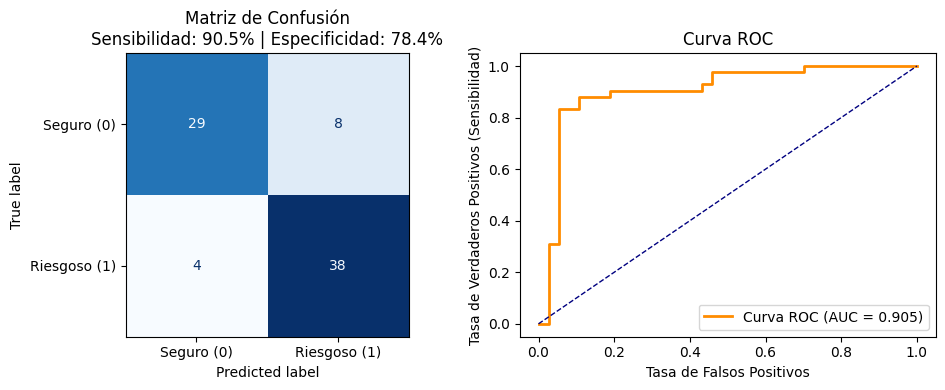

Sensibilidad (Detectar riesgo):  90.48%
Especificidad (Detectar seguro): 78.38%
Área bajo la curva (AUC):        0.905


In [321]:
### Challenge G & D: Confusion Matrix, Sensitivity, Specificity, and ROC Curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# 1. Obtain test set predictions
c_auto.eval()
with torch.no_grad():
    y_test_probs = c_auto(X_test_tens).cpu().numpy().ravel()
    y_test_pred = (y_test_probs >= 0.5).astype(int)
    y_test_true = y_test_tens.cpu().numpy().ravel().astype(int)

# 2. Confusion Matrix
cm = confusion_matrix(y_test_true, y_test_pred)
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn)  # Recall: ability to detect risky cars
specificity = tn / (tn + fp)  # Ability to detect safe cars

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Plot 1: Confusion Matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Safe (0)', 'Risky (1)'])
disp.plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title(f'Confusion Matrix\nSensitivity: {sensitivity*100:.1f}% | Specificity: {specificity*100:.1f}%')

# Plot 2: ROC Curve (Challenge D extra)
fpr, tpr, _ = roc_curve(y_test_true, y_test_probs)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate (Sensitivity)')
ax[1].set_title('ROC Curve')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"Sensitivity (Detect risk):  {sensitivity*100:.2f}%")
print(f"Specificity (Detect safe): {specificity*100:.2f}%")
print(f"Area under curve (AUC):    {roc_auc:.3f}")


---

## Write your observations here

- Task 1: With 4,657 parameters and 400 epochs, the training MSE on the graph decreases, but the test MSE does not, indicating overfitting. On the accuracy graph, there is a significant gap between the test and training sets, indicating overfitting

- Task 2: By setting `shuffle` to `True`, we cause the model to randomly select data from the dataframe, improving the MSE for both training and testing; for accuracy, we see a better range of correct values.

- Task 3: K-best significantly improved the model, as the MSE for both training and testing is low, and for accuracy, both lines (training and testing) are very close to each other, with a value near 90%. PCA caused the test MSE to increase slightly (though it does not harm the model), and for accuracy, the training set exceeded 90% while the test set dropped by only 2%. However, I consider Kbest to be the best option, since the two lines on both graphs are very close to each other.

- Task 4: X_hunch and epochs = 200; training set: 0.17 MSE and test set: 0.20 MSE. X_kbest with epochs = 200: 0.12 MSE on training and 0.13 MSE on testing. Even with fewer epochs, it remains a good model since the MSE values fall within an ideal range, though they increase slightly more; furthermore, with 1,000 epochs, the error rises significantly. With lr = 0.01, considerable overfitting is observed, and with lr = 0.0005, the MSE values for training and testing differ by about 4–5%. Reducing the number of layers greatly helps the model; the MSE values for training and testing remain at 0.2, and the accuracy (ACC) for both remained stable.

- Task 5: With X_hunch, BCELoss() did not work well; when switching to X_pca, the test MSE was 0.37 and the ACC for both was 0.88—a good result for ML

- Task 6: The model learned to classify high-risk cars (97.6%) from low-risk cars (1.6%)

- Task 7: Adapting a classical problem to a quantum computer; the dataset has several columns, but when transitioning to quantum computing, more than half had to be removed. Additionally, we used ordered data rather than random data, and finally, we used MSE, which is designed to predict continuity rather than distinguish between categories.

- Task 8: The classical approach uses neurons, has more than 4,000 parameters, and requires more than 300 epochs—it is instantaneous—while the quantum approach uses qubits that rotate and become entangled, has fewer than 100 parameters, and does not require as many epochs (only 50)—it is slower. However, both are similarly accurate.

- Challenge: I coded the confusion matrix and the ROC curve; I obtained a sensitivity of 90.48, a specificity of 78.38, and an area under the curve of 0.905

- Reflection: As someone with no background in machine learning and only a little knowledge of quantum mechanics, this task helped me understand several things. 1. Using random data from the dataset and a model like PCA, I noticed the difference in the number of parameters between the classical and quantum models. With the sigmoid function, the model learned to classify the cars; this helped me connect my knowledge of data analysis with machine learning, and seeing it in action with quantum methods was fascinating.

## Modifications (do not remove)
Under the [GPL-3.0](https://www.gnu.org/licenses/gpl-3.0.txt) license, if you perform any changes to this notebook, please list them here, adding a note with your name, contact details, date and changes to the code.

- [Jacob Cybulski](http://jacobcybulski.com) (2025, 1 April): The author of this notebook added this section to record all code changes
- [Jacob Cybulski](http://jacobcybulski.com) (2026, 9 April): Now also compatible with...<br>
  pennylane                 0.44.1<br>
  pennylane_lightning       0.44.0<br>
  torch                     2.11.0+cpu<br>
  torchaudio                2.11.0<br>
  torchvision               0.26.0+cpu<br>

## Software (Linux)

In [318]:
import os
os.system('pip list | grep -e pennylane -e torch');